# Лекция 8. Matplotlib

Лекция прочитана Иваном Кисляковым. Разрешено к использованию в некоммерческих образовательных целях.


## 1. Первый график: `plot`

`plot(x, y)` удобно использовать, когда значения по оси `x` имеют естественный порядок: время, номер измерения, координата и т. п.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

В терминале pip install matplotlib

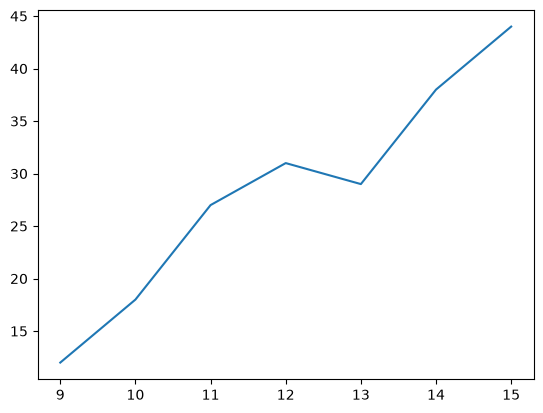

In [2]:
hours = [9, 10, 11, 12, 13, 14, 15]
visitors = [12, 18, 27, 31, 29, 38, 44]

plt.plot(hours, visitors)
plt.show()

По графику уже можно ответить на содержательный вопрос: **в какие часы посещаемость росла, а когда временно снизилась?**

## 2. График функции
Для построения гладкого графика удобно создать много значений `x` с помощью `numpy.linspace`.

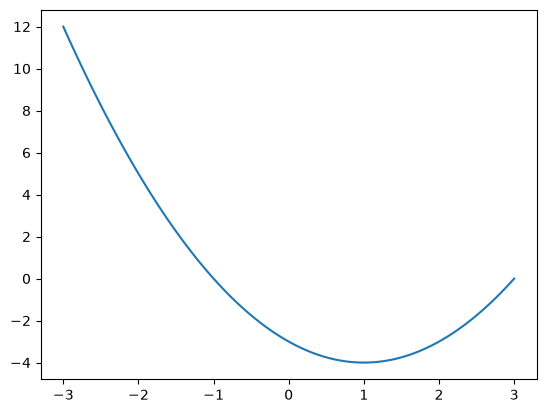

In [5]:
x = np.linspace(-3, 3, 100)
y = x ** 2 - 2 * x - 3

plt.plot(x, y)
plt.show()

Количество точек влияет на гладкость изображения, но не меняет саму математическую функцию.

#### Мини-задание
Постройте на одном поле функции
$
y=x^2,\qquad y=2x+3
$
на отрезке `[-5, 5]`.

По графику оцените, сколько точек пересечения имеют функции и примерно при каких `x` они находятся.


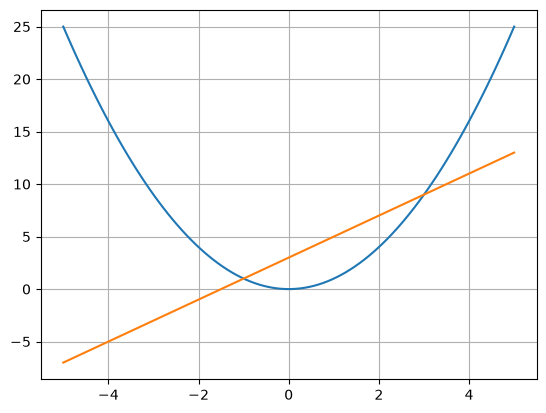

In [13]:
# Ваш код

x = np.linspace(-5, 5, 100)

y_1 = x ** 2
y_2 = 2 * x + 3

plt.plot(x, y_1)
plt.plot(x, y_2)
plt.grid()
plt.show()


## 3. Оформление: заголовок, оси, сетка

Хороший график должен быть понятен без чтения кода.

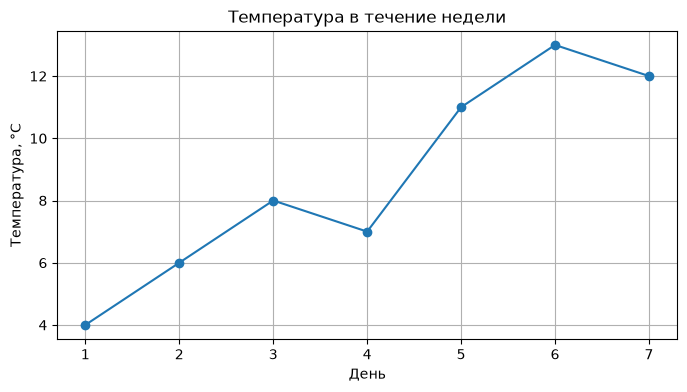

In [12]:
days = [1, 2, 3, 4, 5, 6, 7]
temperature = [4, 6, 8, 7, 11, 13, 12]

plt.figure(figsize=(8, 4))
plt.plot(days, temperature, marker='o')

plt.title('Температура в течение недели')
plt.xlabel('День')
plt.ylabel('Температура, °C')
plt.grid()

plt.show()

## 4. Несколько рядов данных и легенда

Если на одном поле показано несколько величин, необходимо объяснить, какая линия чему соответствует. Для этого каждой серии задают `label`, а затем вызывают `plt.legend()`.


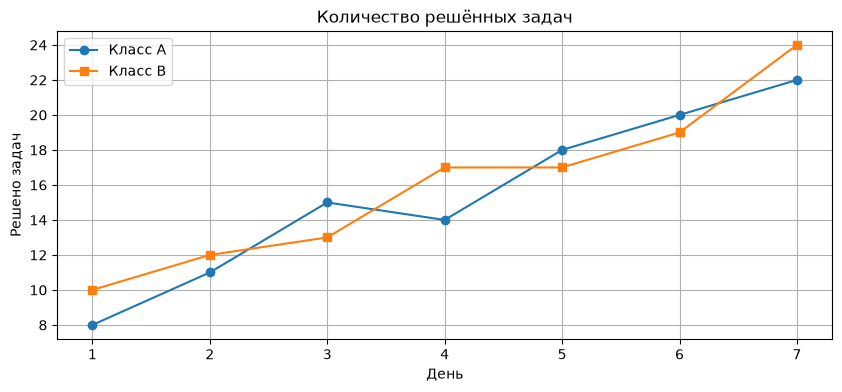

In [15]:
days = np.arange(1, 8)
class_a = [8, 11, 15, 14, 18, 20, 22]
class_b = [10, 12, 13, 17, 17, 19, 24]

plt.figure(figsize=(10, 4))
plt.plot(days, class_a, marker='o', label='Класс A')
plt.plot(days, class_b, marker='s', label='Класс B')

plt.title('Количество решённых задач')
plt.xlabel('День')
plt.ylabel('Решено задач')
plt.grid()

plt.legend()
plt.show()

По такому графику уже можно сравнивать динамику: **кто начал сильнее, когда результаты сравнялись, кто закончил неделю лучше?**

#### Мини-задание
Даны результаты двух групп за четыре контрольные:

```python
tests = [1, 2, 3, 4]
group_1 = [68, 74, 79, 84]
group_2 = [76, 77, 80, 81]
```

Постройте обе линии с понятной легендой и ответьте:
1. Какая группа начала лучше?
2. У какой группы прогресс заметнее?
3. Какие подписи стоит сделать?


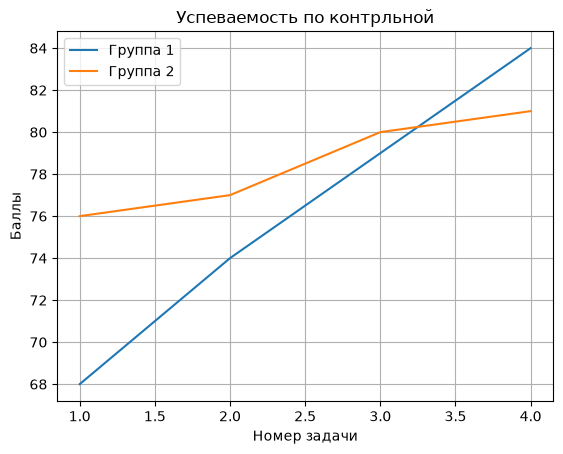

In [21]:
# Ваш код
tests = [1, 2, 3, 4]
group_1 = [68, 74, 79, 84]
group_2 = [76, 77, 80, 81]

plt.plot(tests, group_1, label="Группа 1")
plt.plot(tests, group_2, label="Группа 2")

plt.title("Успеваемость по контрльной")
plt.xlabel("Номер задачи")
plt.ylabel("Баллы")

plt.legend()
plt.grid()
plt.show()


### Как правильно писать легенду

Легенда должна отвечать на вопрос **«что означает эта линия / эти точки / эти столбцы?»**, а не повторять очевидное.

Хороший `label`:
- короткий;
- однозначный;
- содержит название показателя или группы;
- при необходимости содержит единицы измерения или период.

| Неудачно | Лучше |
|---|---|
| `label='Линия 1'` | `label='Класс 10А'` |
| `label='Данные'` | `label='Температура, °C'` |
| `label='График 2025'` | `label='Продажи, 2025'` |
| `label='A'`, `label='B'` | `label='Алгоритм A'`, `label='Алгоритм B'` |

**Когда легенда не нужна:** если на графике только одна серия и её смысл уже ясно указан в заголовке и подписях осей.

**Когда легенда нужна обязательно:** если на одном поле несколько линий, наборов точек или групп столбцов.


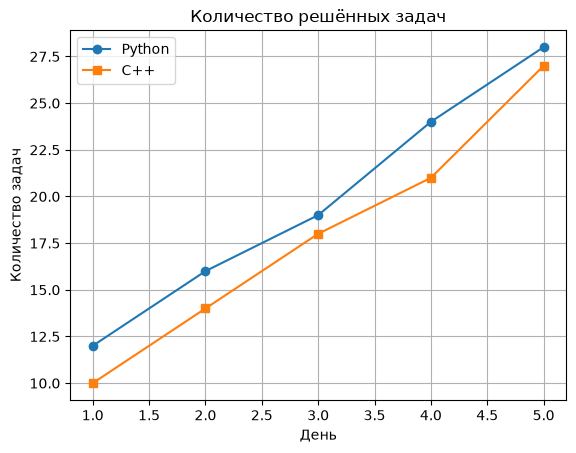

In [22]:
days = [1, 2, 3, 4, 5]
python = [12, 16, 19, 24, 28]
cpp = [10, 14, 18, 21, 27]

plt.plot(days, python, marker='o', label='Python')
plt.plot(days, cpp, marker='s', label='C++')

plt.title('Количество решённых задач')
plt.xlabel('День')
plt.ylabel('Количество задач')
plt.legend()
plt.grid()
plt.show()


Обратите внимание: подписи `Python` и `C++` сообщают **смысл серий**, а подписи осей сообщают **смысл координат**. Это разные задачи.

#### Мини-задание
Исправьте плохие подписи в коде ниже:

```python
plt.plot(days, python, label='График 1')
plt.plot(days, cpp, label='График 2')
```

Подберите такие `label`, чтобы график был понятен человеку, который не видел код.


## 5. `scatter`: связь между двумя числовыми величинами

`scatter` полезен, когда точки не обязаны соединяться линией. Например, можно проверить, есть ли связь между временем подготовки и результатом работы.

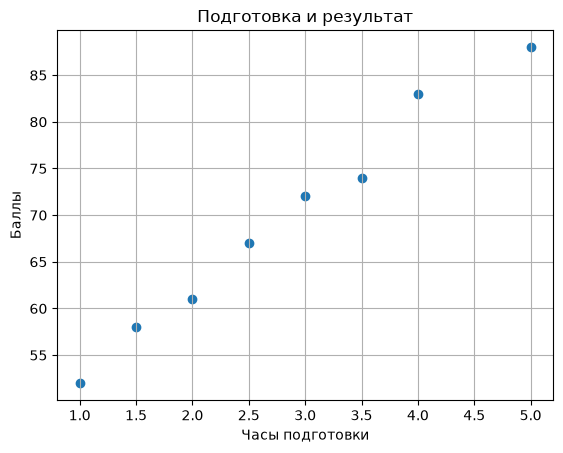

In [23]:
study_hours = [1, 1.5, 2, 2.5, 3, 3.5, 4, 5]
score = [52, 58, 61, 67, 72, 74, 83, 88]

plt.scatter(study_hours, score)
plt.title('Подготовка и результат')
plt.xlabel('Часы подготовки')
plt.ylabel('Баллы')
plt.grid()
plt.show()

График не доказывает причинно-следственную связь, но позволяет визуально заметить тенденцию.

#### Мини-задание
Для восьми программ известны размер исходного кода и время запуска:

```python
lines = [80, 120, 150, 210, 260, 310, 390, 450]
start_ms = [35, 41, 44, 52, 55, 63, 67, 76]
```

Постройте `scatter` и сформулируйте один аккуратный вывод о видимой связи между величинами.


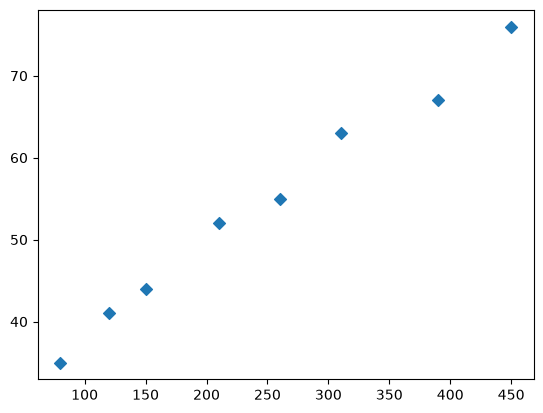

In [24]:
# Ваш код
lines = [80, 120, 150, 210, 260, 310, 390, 450]
start_ms = [35, 41, 44, 52, 55, 63, 67, 76]

plt.scatter(lines, start_ms, marker='D')
plt.show()

## 6. Стиль линий и маркеров

### Шпаргалка: `label`, `marker`, `linestyle`

#### `label` — подпись линии или набора данных

Значение `label` — это **произвольный текст**, который будет показан в легенде после вызова `plt.legend()`.

| Пример | Что появится в легенде |
|---|---|
| `label='sin(x)'` | `sin(x)` |
| `label='Эксперимент'` | `Эксперимент` |
| `label='2025 год'` | `2025 год` |

#### `marker` — вид маркера точки

| Значение | Вид маркера |
|---|---|
| `'.'` | точка |
| `','` | маленький пиксель |
| `'o'` | круг |
| `'s'` | квадрат |
| `'^'` | треугольник вверх |
| `'v'` | треугольник вниз |
| `'<'` | треугольник влево |
| `'>'` | треугольник вправо |
| `'D'` | ромб |
| `'*'` | звезда |
| `'+'` | плюс |
| `'x'` | крестик |
| `'None'` или без `marker` | без маркеров |

#### `linestyle` — стиль линии

| Значение | Сокращение | Вид линии |
|---|---|---|
| `'solid'` | `'-'` | сплошная |
| `'dashed'` | `'--'` | штриховая |
| `'dashdot'` | `'-.'` | штрих-точка |
| `'dotted'` | `':'` | пунктирная |
| `'None'` | `''` | без линии |

Пример совместного использования:

```python
plt.plot(x, y, label='Данные', marker='o', linestyle='--')
plt.legend()
```



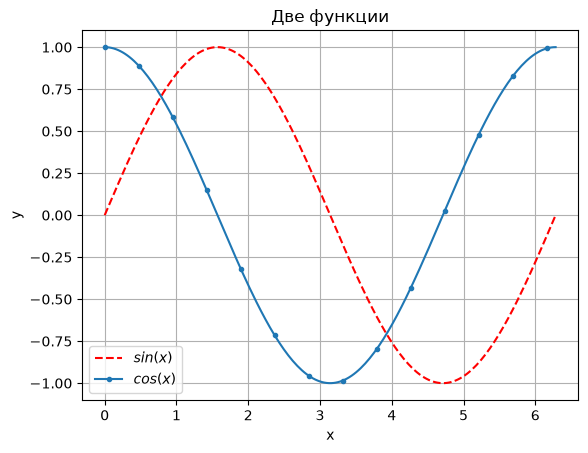

In [31]:
x = np.linspace(0, 2 * np.pi, 200)

plt.plot(x, np.sin(x), linestyle='--', label='$sin(x)$', color="red")
plt.plot(x, np.cos(x), marker='.', markevery=15, label='$cos(x)$')
plt.title('Две функции')
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.show()

Стиль должен помогать различать данные, а не отвлекать от них.

## 7. Столбчатая диаграмма: `bar`

`bar` подходит для сравнения **категорий**.

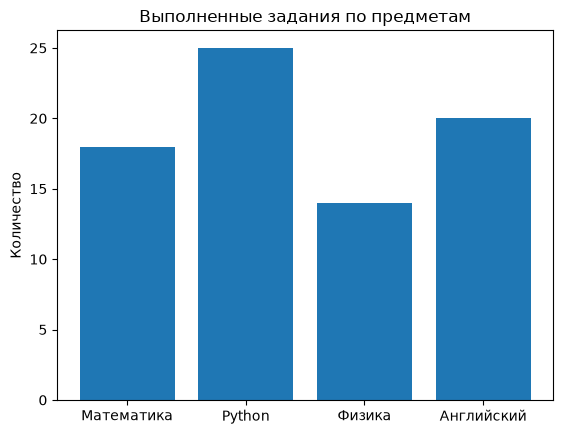

In [32]:
subjects = ['Математика', 'Python', 'Физика', 'Английский']
completed = [18, 25, 14, 20]

plt.bar(subjects, completed)
plt.title('Выполненные задания по предметам')
plt.ylabel('Количество')
plt.show()

Здесь соединять значения линией было бы бессмысленно: между названиями предметов нет непрерывной числовой шкалы.

#### Мини-задание
Даны количества заявок по четырём направлениям:

```python
directions = ['Web', 'Data', 'Robotics', 'Design']
applications = [42, 31, 27, 18]
```

Постройте столбчатую диаграмму и определите:
1. самое популярное направление;
2. разницу между максимумом и минимумом;


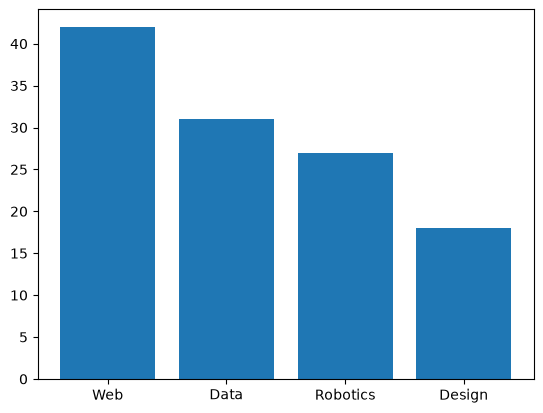

In [33]:
# Ваш код
directions = ['Web', 'Data', 'Robotics', 'Design']
applications = [42, 31, 27, 18]

plt.bar(directions, applications)
plt.show()

## 8. Круговая диаграмма: `pie`

`pie` можно использовать, если нужно показать части одного целого и категорий немного.

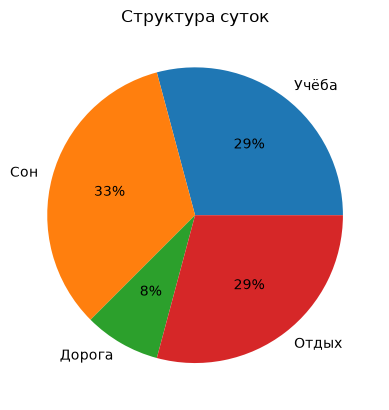

In [38]:
activities = ['Учёба', 'Сон', 'Дорога', 'Отдых']
hours = [7, 8, 2, 7]

plt.pie(hours, labels=activities, autopct='%1.0f%%')
plt.title('Структура суток')
plt.show()

Если категорий много или значения близки, обычно удобнее `bar`, а не `pie`.

#### Мини-задание
У проекта бюджет распределён так:

```python
parts = ['Разработка', 'Дизайн', 'Тестирование', 'Инфраструктура']
budget = [45, 15, 20, 20]
```

Постройте круговую диаграмму и ответьте: какие две статьи имеют одинаковую долю?


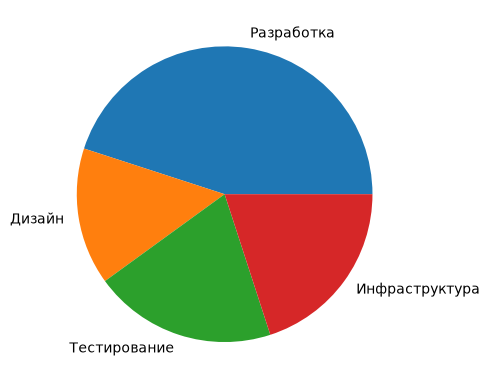

In [39]:
# Ваш код
parts = ['Разработка', 'Дизайн', 'Тестирование', 'Инфраструктура']
budget = [45, 15, 20, 20]

plt.pie(budget, labels=parts)
plt.show()

## 9. Несколько графиков: `subplots`

Иногда сравнивать графики на одном поле неудобно. Тогда лучше разместить их рядом.

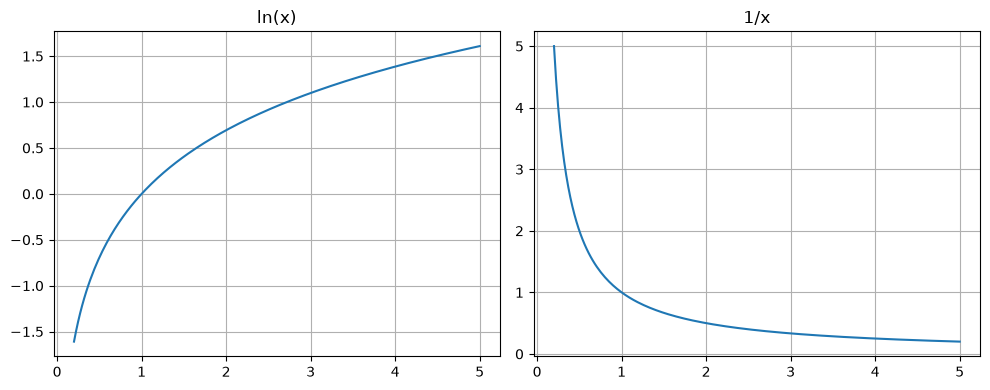

In [40]:
x = np.linspace(0.2, 5, 200)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(x, np.log(x))
ax[0].set_title('ln(x)')
ax[0].grid()

ax[1].plot(x, 1/x)
ax[1].set_title('1/x')
ax[1].grid()

plt.tight_layout()
plt.show()

## 10. Логарифмический масштаб

Он полезен, когда значения отличаются на порядки величины.

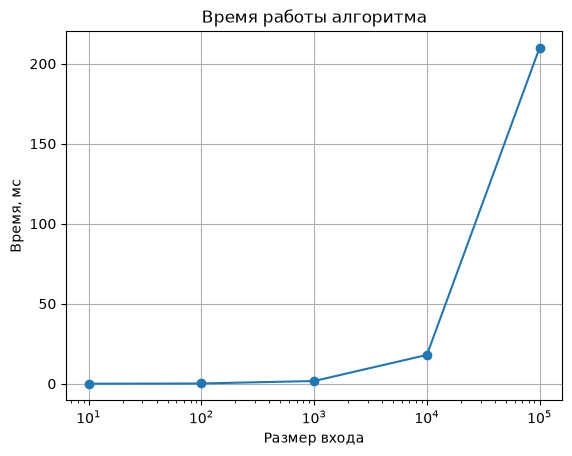

In [44]:
n = [10, 100, 1000, 10000, 100000]
time_ms = [0.02, 0.15, 1.7, 18, 210]

plt.plot(n, time_ms, marker='o')
plt.xscale('log')


plt.title('Время работы алгоритма')
plt.xlabel('Размер входа')
plt.ylabel('Время, мс')
plt.grid()
plt.show()

## 11. Чтение данных из CSV

Пусть файл `visitors.csv` содержит:

```text
day,visitors
Пн,120
Вт,150
Ср,143
Чт,181
Пт,210
```

Удобнее всего использовать `csv.DictReader`: тогда к значениям можно обращаться по названиям столбцов.


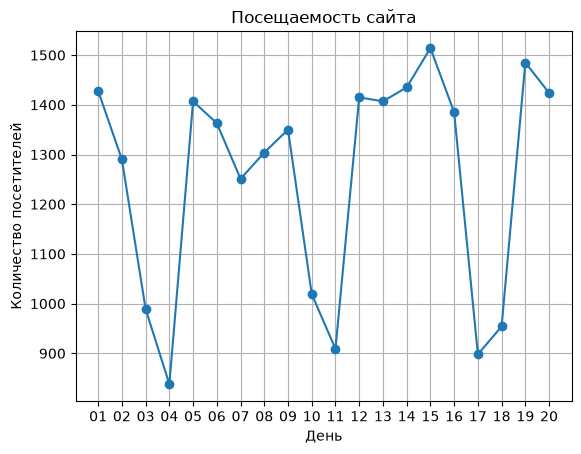

In [48]:
import csv
import matplotlib.pyplot as plt

days = []
visitors = []

with open('visitors.csv', encoding='utf-8') as file:
    reader = csv.DictReader(file)

    for row in reader:
        days.append(row['day'])
        visitors.append(int(row['visitors']))

days = list(map(lambda line: line[-2:], days))
days_1 = days[:20]
visitors_1 = visitors[:20]

plt.plot(days_1, visitors_1, marker='o')
plt.title('Посещаемость сайта')
plt.xlabel('День')
plt.ylabel('Количество посетителей')
plt.grid()
plt.show()


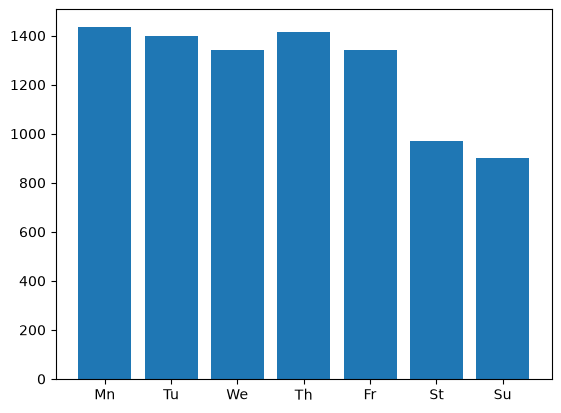

In [55]:
d1 = visitors_1[4::7]
d2 = visitors_1[5::7]
d3 = visitors_1[6::7]
d4 = visitors_1[0::7]
d5 = visitors_1[1::7]
d6 = visitors_1[2::7]
d7 = visitors_1[3::7]
d1 = sum(d1) / len(d1)
d2 = sum(d2) / len(d2)
d3 = sum(d3) / len(d3)
d4 = sum(d4) / len(d4)
d5 = sum(d5) / len(d5)
d6 = sum(d6) / len(d6)
d7 = sum(d7) / len(d7)

data = [d1, d2, d3, d4, d5, d6, d7]
plt.bar(["Mn", "Tu", "We", "Th", "Fr", "St", "Su"], data)
plt.show()

Здесь происходит три отдельных шага:

1. **читаем строки** из CSV;
2. **преобразуем значения** в нужный тип (`int` или `float`);
3. **визуализируем** полученные списки.

Это важное разделение: Matplotlib отвечает за визуализацию, а модуль `csv` — за чтение файла.

#### Мини-задание
Пусть файл `temperature.csv` имеет столбцы `month` и `temperature`.

1. Считайте данные через `csv.DictReader`.
2. Постройте линейный график.
3. Добавьте маркеры, заголовок и подписи осей.
4. По графику определите месяц с максимальной температурой.


In [ ]:
# Ваш код


## 13. Задачи для закрепления

### Задача 1. Посещаемость курса
За шесть занятий число присутствующих студентов было:

```python
lessons = [1, 2, 3, 4, 5, 6]
students = [31, 29, 30, 25, 27, 24]
```

Постройте график и найдите:
- максимальную посещаемость;
- занятие с минимальной посещаемостью;
- общий характер изменения.

### Задача 2. Сравнение двух версий программы
```python
n = [100, 500, 1000, 5000, 10000]
old = [8, 35, 74, 390, 810]
new = [6, 24, 51, 255, 530]
```

Постройте обе серии на одном поле. Подберите хорошую легенду. Сделайте вывод, какая версия работает быстрее и увеличивается ли разница с ростом `n`.

### Задача 3. Выберите тип графика
Для каждого набора выберите `plot`, `scatter`, `bar` или `pie` и объясните решение:
1. число посетителей сайта по дням месяца;
2. цена восьми товаров и их рейтинг;
3. количество студентов на пяти направлениях;
4. доли расходов проекта.

### Задача 4. Из CSV
Создайте небольшой CSV-файл с результатами соревнования: `team,score`. Считайте его без Pandas и постройте диаграмму, по которой легко определить победителя.
